<div style=" background-color: RGB(0,114,200);" >
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 4 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Réalisez une étude de santé publique avec R ou Python
</h2>
</div>

# OBJECTIF DE CE NOTEBOOK

Bienvenue dans l'outil plébiscité par les analystes de données Jupyter.

Il s'agit d'un outil permettant de mixer et d'alterner codes, textes et graphique.

Cet outil est formidable pour plusieurs raisons:

+ il permet de tester des lignes de codes au fur et à mesure de votre rédaction, de constater immédiatement le résultat d'un instruction, de la corriger si nécessaire.
+ De rédiger du texte pour expliquer l'approche suivie ou les résultats d'une analyse et de le mettre en forme grâce à du code html ou plus simple avec **Markdown**
+ d'agrémenter de graphiques

Pour vous aider dans vos premiers pas à l'usage de Jupyter et de Python, nous avons rédigé ce notebook en vous indiquant les instructions à suivre.

Il vous suffit pour cela de saisir le code Python répondant à l'instruction donnée.

Vous verrez de temps à autre le code Python répondant à une instruction donnée mais cela est fait pour vous aider à comprendre la nature du travail qui vous est demandée.

Et garder à l'esprit, qu'il n'y a pas de solution unique pour résoudre un problème et qu'il y a autant de résolutions de problèmes que de développeurs ;)...



<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 - Importation des librairies</h3>
</div>

In [1]:
#Importation de la librairie Pandas et autres librairies nécessaires à la réalisation des graphiques et cartes
%pip install plotly pycountry country_converter deep-translator

import pandas as pd
import matplotlib.pyplot as plt
import pycountry
import plotly.express as px
import numpy as np


Note: you may need to restart the kernel to use updated packages.


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Chargement des fichiers Excel</h3>
</div>

In [2]:
#Importation du fichier population.csv
population = pd.read_csv('C:/Users/capel/Downloads/Projet 4/DAN-P4-FAO/population.csv')

#Importation du fichier dispo_alimentaire.csv
dispo_alimentaire = pd.read_csv('C:/Users/capel/Downloads/Projet 4/DAN-P4-FAO/dispo_alimentaire.csv')

#Importation du fichier aide_alimentaire.csv
aide_alimentaire = pd.read_csv('C:/Users/capel/Downloads/Projet 4/DAN-P4-FAO/aide_alimentaire.csv')

#Importation du fichier sous_nutrition.csv
sous_nutrition = pd.read_csv('C:/Users/capel/Downloads/Projet 4/DAN-P4-FAO/sous_nutrition.csv')


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.1 - Analyse exploratoire du fichier population</h3>
</div>

In [3]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(population.shape[0]))
print("Le tableau comporte {} colonne(s)".format(population.shape[1]))

Le tableau comporte 1416 observation(s) ou article(s)
Le tableau comporte 3 colonne(s)


In [4]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(population.shape[1]))
#La nature des données dans chacune des colonnes
print("La nature des données dans chacune des colonnes est :")
print(population.dtypes)
#Le nombre de valeurs présentes dans chacune des colonnes
print("Le nombre de valeurs présentes dans chacune des colonnes est :")
print(pd.DataFrame(population).count())


Le tableau comporte 3 colonne(s)
La nature des données dans chacune des colonnes est :
Zone       object
Année       int64
Valeur    float64
dtype: object
Le nombre de valeurs présentes dans chacune des colonnes est :
Zone      1416
Année     1416
Valeur    1416
dtype: int64


In [5]:
#Affichage les 5 premières lignes de la table
print("Les 5 premières lignes sont :")
display(population.head())

Les 5 premières lignes sont :


,Zone,Année,Valeur
0,Afghanistan,2013,32269.589
1,Afghanistan,2014,33370.794
2,Afghanistan,2015,34413.603
3,Afghanistan,2016,35383.032
4,Afghanistan,2017,36296.113


In [6]:
#Nous allons harmoniser les unités. Pour cela, nous avons décidé de multiplier la population par 1000
#Multiplication de la colonne valeur par 1000
population['Valeur'] = population['Valeur']*1000
population['Valeur'] = population['Valeur'].astype(int)


In [7]:
#changement du nom de la colonne Valeur par Population
population.rename(columns={'Valeur': 'Population'}, inplace=True)

In [8]:
#Affichage les 5 premières lignes de la table pour voir les modifications
display(population.head())

,Zone,Année,Population
0,Afghanistan,2013,32269589
1,Afghanistan,2014,33370794
2,Afghanistan,2015,34413603
3,Afghanistan,2016,35383032
4,Afghanistan,2017,36296113


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.2 - Analyse exploratoire du fichier disponibilité alimentaire</h3>
</div>

In [9]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(dispo_alimentaire.shape[0]))
print("Le tableau comporte {} colonne(s)".format(dispo_alimentaire.shape[1]))

Le tableau comporte 15605 observation(s) ou article(s)
Le tableau comporte 18 colonne(s)


In [10]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(dispo_alimentaire.shape[1]))

Le tableau comporte 18 colonne(s)


In [11]:
#Affichage les 5 premières lignes de la table
display(dispo_alimentaire.head())

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,NaN,NaN,5.0,1.72,0.20,0.77,53.0,NaN,NaN,53.0,NaN,53.0,NaN,NaN,NaN
1,Afghanistan,"Agrumes, Autres",vegetale,NaN,NaN,1.0,1.29,0.01,0.02,41.0,2.0,40.0,39.0,2.0,3.0,NaN,NaN,NaN
2,Afghanistan,Aliments pour enfants,vegetale,NaN,NaN,1.0,0.06,0.01,0.03,2.0,NaN,2.0,2.0,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,Ananas,vegetale,NaN,NaN,0.0,0.00,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,Bananes,vegetale,NaN,NaN,4.0,2.70,0.02,0.05,82.0,NaN,82.0,82.0,NaN,NaN,NaN,NaN,NaN


In [12]:
#remplacement des NaN dans le dataset par des 0

dispo_alimentaire = dispo_alimentaire.fillna(0)

In [13]:
#multiplication de toutes les lignes contenant des milliers de tonnes en Kg
colonnes_multiplier = [
    'Aliments pour animaux', 'Autres Utilisations', 'Disponibilité intérieure', 
    'Exportations - Quantité', 'Importations - Quantité', 'Nourriture', 
    'Pertes', 'Production', 'Semences', 'Traitement', 'Variation de stock'
]
dispo_alimentaire.loc[:, colonnes_multiplier] = dispo_alimentaire.loc[:, colonnes_multiplier]*1000

In [14]:
#Affichage les 5 premières lignes de la table
display(dispo_alimentaire.head())

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock
0,Afghanistan,Abats Comestible,animale,0.0,0.0,5.0,1.72,0.20,0.77,53000.0,0.0,0.0,53000.0,0.0,53000.0,0.0,0.0,0.0
1,Afghanistan,"Agrumes, Autres",vegetale,0.0,0.0,1.0,1.29,0.01,0.02,41000.0,2000.0,40000.0,39000.0,2000.0,3000.0,0.0,0.0,0.0
2,Afghanistan,Aliments pour enfants,vegetale,0.0,0.0,1.0,0.06,0.01,0.03,2000.0,0.0,2000.0,2000.0,0.0,0.0,0.0,0.0,0.0
3,Afghanistan,Ananas,vegetale,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Afghanistan,Bananes,vegetale,0.0,0.0,4.0,2.70,0.02,0.05,82000.0,0.0,82000.0,82000.0,0.0,0.0,0.0,0.0,0.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire du fichier aide alimentaire</h3>
</div>

In [15]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(aide_alimentaire.shape[0]))
print("Le tableau comporte {} colonne(s)".format(aide_alimentaire.shape[1]))

Le tableau comporte 1475 observation(s) ou article(s)
Le tableau comporte 4 colonne(s)


In [16]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(aide_alimentaire.shape[1]))

Le tableau comporte 4 colonne(s)


In [17]:
#Affichage les 5 premières lignes de la table
display(aide_alimentaire.head())

,Pays bénéficiaire,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682
1,Afghanistan,2014,Autres non-céréales,335
2,Afghanistan,2013,Blé et Farin,39224
3,Afghanistan,2014,Blé et Farin,15160
4,Afghanistan,2013,Céréales,40504


In [18]:
#changement du nom de la colonne Pays bénéficiaire par Zone
aide_alimentaire.rename(columns={'Pays bénéficiaire': 'Zone'}, inplace=True)

In [19]:
#Multiplication de la colonne Aide_alimentaire qui contient des tonnes par 1000 pour avoir des kg
aide_alimentaire['Valeur'] = aide_alimentaire['Valeur']*1000

In [20]:
#Affichage les 5 premières lignes de la table
display(aide_alimentaire.head())

,Zone,Année,Produit,Valeur
0,Afghanistan,2013,Autres non-céréales,682000
1,Afghanistan,2014,Autres non-céréales,335000
2,Afghanistan,2013,Blé et Farin,39224000
3,Afghanistan,2014,Blé et Farin,15160000
4,Afghanistan,2013,Céréales,40504000


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.4 - Analyse exploratoire du fichier sous nutrition</h3>
</div>

In [21]:
#Afficher les dimensions du dataset
print("Le tableau comporte {} observation(s) ou article(s)".format(sous_nutrition.shape[0]))
print("Le tableau comporte {} colonne(s)".format(sous_nutrition.shape[1]))

Le tableau comporte 1218 observation(s) ou article(s)
Le tableau comporte 3 colonne(s)


In [22]:
#Consulter le nombre de colonnes
print("Le tableau comporte {} colonne(s)".format(sous_nutrition.shape[1]))

Le tableau comporte 3 colonne(s)


In [23]:
#Afficher les 5 premières lignes de la table
display(sous_nutrition.head())

,Zone,Année,Valeur
0,Afghanistan,2012-2014,8.6
1,Afghanistan,2013-2015,8.8
2,Afghanistan,2014-2016,8.9
3,Afghanistan,2015-2017,9.7
4,Afghanistan,2016-2018,10.5


In [24]:
#Conversion de la colonne sous nutrition en numérique
print(sous_nutrition.columns)
sous_nutrition_valeur = sous_nutrition.copy()
sous_nutrition_valeur['Valeur'] = pd.to_numeric(sous_nutrition_valeur['Valeur'], errors='coerce')

Index(['Zone', 'Année', 'Valeur'], dtype='object')


In [25]:
#Conversion de la colonne (avec l'argument errors=coerce qui permet de convertir automatiquement les lignes qui ne sont pas des nombres en NaN)
#Puis remplacement des NaN en 0
sous_nutrition_valeur['Valeur'] = sous_nutrition_valeur['Valeur'].fillna(0)

In [26]:
#changement du nom de la colonne Valeur par sous_nutrition
sous_nutrition_valeur.rename(columns={'Valeur': 'sous_nutrition'}, inplace=True)

In [27]:
#Multiplication de la colonne sous_nutrition par 1000000
sous_nutrition_valeur['sous_nutrition'] = sous_nutrition_valeur['sous_nutrition']*1000000

In [28]:
#Afficher les 5 premières lignes de la table
display(sous_nutrition_valeur.head())

,Zone,Année,sous_nutrition
0,Afghanistan,2012-2014,8600000.0
1,Afghanistan,2013-2015,8800000.0
2,Afghanistan,2014-2016,8900000.0
3,Afghanistan,2015-2017,9700000.0
4,Afghanistan,2016-2018,10500000.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.1 - Proportion de personnes en sous nutrition</h3>
</div>

In [29]:
# Il faut tout d'abord faire une jointure entre la table population et la table sous nutrition, en ciblant l'année 2017

sous_nutrition_2017 = sous_nutrition_valeur.copy()

population_2017 = population[population['Année'] == 2017]
sous_nutrition_2017 = sous_nutrition_2017.replace('2016-2018', '2017')
sous_nutrition_2017 = sous_nutrition_2017[sous_nutrition_2017['Année'] == '2017']

sous_nutrition_2017['Année'] = sous_nutrition_2017['Année'].astype(int)

data_2017 = pd.merge(population_2017, sous_nutrition_2017, on=['Zone', 'Année'])

In [30]:
#Affichage du dataset
display(data_2017.head())

,Zone,Année,Population,sous_nutrition
0,Afghanistan,2017,36296113,10500000.0
1,Afrique du Sud,2017,57009756,3100000.0
2,Albanie,2017,2884169,100000.0
3,Algérie,2017,41389189,1300000.0
4,Allemagne,2017,82658409,0.0


In [31]:
#Calcul et affichage le nombre de personnes en état de sous nutrition

for elt in data_2017:
    if elt == 'sous_nutrition':
        print(f"{'Sous-nutrition'}: {data_2017[elt].sum().astype(int)} individus sont en état de sous-nutrition")
        proportion = data_2017[elt].sum() / data_2017['Population'].sum() * 100

print('Proportion:', proportion.round(2), '% de la population mondiale')

Sous-nutrition: 535700000 individus sont en état de sous-nutrition
Proportion: 7.1 % de la population mondiale


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.2 - Nombre théorique de personne qui pourrait être nourries</h3>
</div>

In [32]:
#Combien mange en moyenne un être humain ? Source =>

<p>Selon J.-P. Charvet, la ration alimentaire moyenne nécessaire est de 2500 kcal/personne/jour</p>
<a href="https://fr.wikipedia.org/wiki/Ration_alimentaire" target="_blank">https://fr.wikipedia.org/wiki/Ration_alimentaire</a>

In [33]:
#On commence par faire une jointure entre le data frame population et Dispo_alimentaire afin d'ajouter dans ce dernier la population
dispo_alimentaire_population = pd.merge(dispo_alimentaire, population[population['Année'] == 2017][['Zone', 'Population']], on='Zone', how='left')

In [34]:
#Affichage du nouveau dataframe
display(dispo_alimentaire_population.head())

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock,Population
0,Afghanistan,Abats Comestible,animale,0.0,0.0,5.0,1.72,0.20,0.77,53000.0,0.0,0.0,53000.0,0.0,53000.0,0.0,0.0,0.0,36296113.0
1,Afghanistan,"Agrumes, Autres",vegetale,0.0,0.0,1.0,1.29,0.01,0.02,41000.0,2000.0,40000.0,39000.0,2000.0,3000.0,0.0,0.0,0.0,36296113.0
2,Afghanistan,Aliments pour enfants,vegetale,0.0,0.0,1.0,0.06,0.01,0.03,2000.0,0.0,2000.0,2000.0,0.0,0.0,0.0,0.0,0.0,36296113.0
3,Afghanistan,Ananas,vegetale,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,36296113.0
4,Afghanistan,Bananes,vegetale,0.0,0.0,4.0,2.70,0.02,0.05,82000.0,0.0,82000.0,82000.0,0.0,0.0,0.0,0.0,0.0,36296113.0


In [35]:
#Création de la colonne dispo_kcal avec calcul des kcal disponibles mondialement

group_zone = dispo_alimentaire_population.groupby('Zone').agg({
    'Disponibilité alimentaire (Kcal/personne/jour)': 'sum',
    'Population': 'first'
})

group_zone.rename(
    columns={'Disponibilité alimentaire (Kcal/personne/jour)': 'Disponibilité alimentaire'},
    inplace=True
)

group_zone['dispo_kcal'] = (
    group_zone['Disponibilité alimentaire']
    * group_zone['Population']
)

kcal_world = group_zone['dispo_kcal'].sum()

In [36]:
#Calcul du nombre d'humains pouvant être nourris
kcal_mean = 2500
number_of_humans = kcal_world / kcal_mean
print(number_of_humans.astype(int), "personnes pourraient être nourries chaque jour")

8367593843 personnes pourraient être nourries chaque jour


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.3 - Nombre théorique de personne qui pourrait être nourrie avec les produits végétaux</h3>
</div>

In [37]:
#Transfert des données avec les végétaux dans un nouveau dataframe
vegetaux = pd.merge(dispo_alimentaire, population[population['Année'] == 2017][['Zone', 'Population']], on='Zone', how='left')

vegetaux.rename(
    columns={'Disponibilité alimentaire (Kcal/personne/jour)': 'Disponibilité alimentaire'},
    inplace=True
)

vegetaux = vegetaux[vegetaux['Origine'] == 'vegetale']
vegetaux = vegetaux.groupby('Zone').agg({
    'Produit': 'count',
    'Disponibilité alimentaire': 'sum',
    'Population': 'first'
})

In [38]:
#Calcul du nombre de kcal disponible pour les végétaux
vegetaux['dispo_kcal'] = (
    vegetaux['Disponibilité alimentaire']
    * vegetaux['Population']
)
kcal_vegetal_sum = vegetaux['dispo_kcal'].sum()

In [39]:
#Calcul du nombre d'humains pouvant être nourris avec les végétaux
number_of_humans_veg = kcal_vegetal_sum / kcal_mean

print(number_of_humans_veg.astype(int), 'personnes pouvant être nourries par jour avec uniquement les végétaux')

6904305678 personnes pouvant être nourries par jour avec uniquement les végétaux


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.4 - Utilisation de la disponibilité intérieure</h3>
</div>

In [40]:
#Calcul de la disponibilité totale

#Dispo totale = Production + Importations - Exportations - Pertes - Usage non alimentaire +/- Variation de stock

dispo_alimentaire['Disponibilité totale'] = (dispo_alimentaire['Production'] + dispo_alimentaire['Importations - Quantité'] - dispo_alimentaire['Exportations - Quantité'] - dispo_alimentaire['Pertes'] - dispo_alimentaire['Semences'] - dispo_alimentaire['Traitement'] - dispo_alimentaire['Aliments pour animaux'] - dispo_alimentaire['Autres Utilisations'] + dispo_alimentaire['Variation de stock'])

display(dispo_alimentaire.head())

,Zone,Produit,Origine,Aliments pour animaux,Autres Utilisations,Disponibilité alimentaire (Kcal/personne/jour),Disponibilité alimentaire en quantité (kg/personne/an),Disponibilité de matière grasse en quantité (g/personne/jour),Disponibilité de protéines en quantité (g/personne/jour),Disponibilité intérieure,Exportations - Quantité,Importations - Quantité,Nourriture,Pertes,Production,Semences,Traitement,Variation de stock,Disponibilité totale
0,Afghanistan,Abats Comestible,animale,0.0,0.0,5.0,1.72,0.20,0.77,53000.0,0.0,0.0,53000.0,0.0,53000.0,0.0,0.0,0.0,53000.0
1,Afghanistan,"Agrumes, Autres",vegetale,0.0,0.0,1.0,1.29,0.01,0.02,41000.0,2000.0,40000.0,39000.0,2000.0,3000.0,0.0,0.0,0.0,39000.0
2,Afghanistan,Aliments pour enfants,vegetale,0.0,0.0,1.0,0.06,0.01,0.03,2000.0,0.0,2000.0,2000.0,0.0,0.0,0.0,0.0,0.0,2000.0
3,Afghanistan,Ananas,vegetale,0.0,0.0,0.0,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Afghanistan,Bananes,vegetale,0.0,0.0,4.0,2.70,0.02,0.05,82000.0,0.0,82000.0,82000.0,0.0,0.0,0.0,0.0,0.0,82000.0


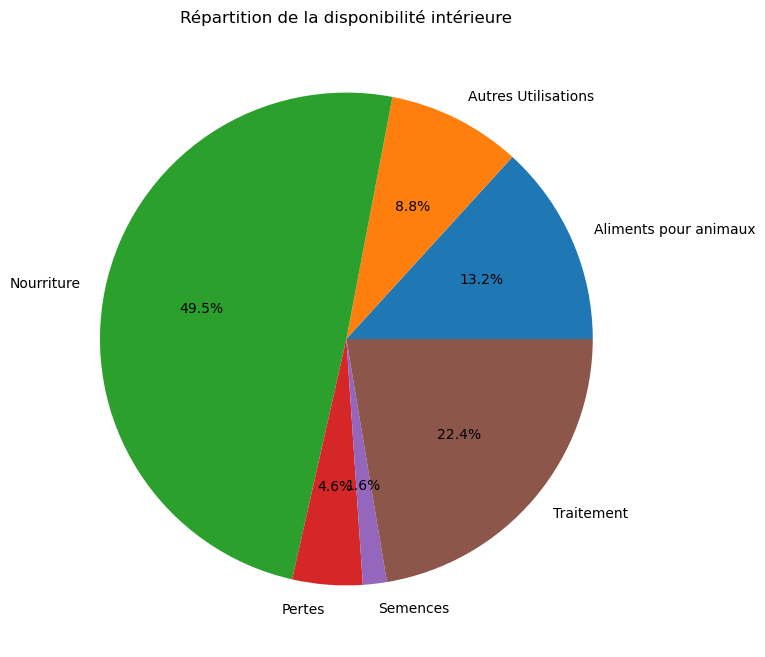

In [41]:
#création d'une boucle for pour afficher les différentes valeurs en fonction des colonnes aliments 
# pour animaux, pertes, nourritures, semences, traitement, autres utilisations

ratios_ignore = [
    "Produit",
    "Origine",
    "Disponibilité alimentaire (Kcal/personne/jour)",
    "Disponibilité alimentaire en quantité (kg/personne/an)",
    "Disponibilité de matière grasse en quantité (g/personne/jour)",
    "Disponibilité de protéines en quantité (g/personne/jour)",
    "Production",
    "Exportations - Quantité",
    "Importations - Quantité",
    "Variation de stock",
    "Disponibilité totale"
]

columns = []
values = []

ratio = dispo_alimentaire.drop(columns=ratios_ignore).copy().groupby('Zone', as_index=False).sum()

dispo_sum = ratio['Disponibilité intérieure'].sum()

for elt in ratio.columns:
    if elt not in ['Zone', 'Disponibilité intérieure']:
        try:
            part = ratio[elt].sum() / dispo_sum * 100
            columns.append(elt)
            values.append(part)
        except KeyError:
            pass

plt.figure(figsize=(8, 8))
plt.pie(
    values,
    labels=columns,
    autopct='%1.1f%%',
)
plt.title("Répartition de la disponibilité intérieure")
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.5 - Utilisation des céréales</h3>
</div>

In [42]:
#Création d'une liste avec toutes les variables
uniques_aliments = dispo_alimentaire['Produit'].unique()

uniques_aliments = pd.Series(dispo_alimentaire['Produit'].unique())

list_cereales = [
    'Blé',
    'Maïs',
    'Millet',
    'Orge',
    'Riz (Eq Blanchi)',
    'Seigle',
    'Avoine',
    'Sorgho',
    'Céréales, Autres',
]

print(list_cereales)
#9 items

['Blé', 'Maïs', 'Millet', 'Orge', 'Riz (Eq Blanchi)', 'Seigle', 'Avoine', 'Sorgho', 'Céréales, Autres']


In [43]:
#Création d'un dataframe avec les informations uniquement pour ces céréales
import re

pattern = '|'.join([re.escape(p) for p in list_cereales])

cereales = dispo_alimentaire[dispo_alimentaire['Produit'].isin(list_cereales)].copy()


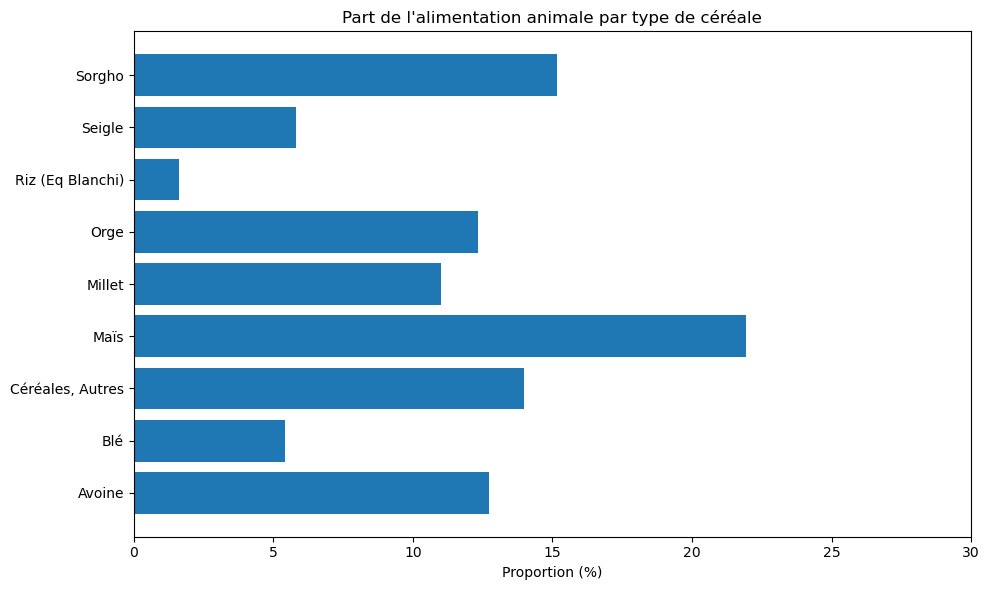

In [44]:
#Affichage de la proportion d'alimentation animale
cereales['Proportion alimentation animale'] = (cereales['Aliments pour animaux'] / cereales['Disponibilité intérieure']*100).round(2)
cereales['Proportion alimentation animale'] = cereales['Proportion alimentation animale'].fillna(0)

prop_cereales_animaux = cereales[['Zone', 'Produit', 'Proportion alimentation animale']]
cereales_pie_anim = prop_cereales_animaux.groupby('Produit')['Proportion alimentation animale'].sum() 
cereales_pct = (cereales_pie_anim / cereales_pie_anim.sum() * 100).round(2)

plt.figure(figsize=(10, 6))

plt.barh(
    cereales_pct.index,
    cereales_pct.values
)

plt.xlabel('Proportion (%)')
plt.title("Part de l'alimentation animale par type de céréale")
plt.xlim(0, 30)

plt.tight_layout()
plt.show()

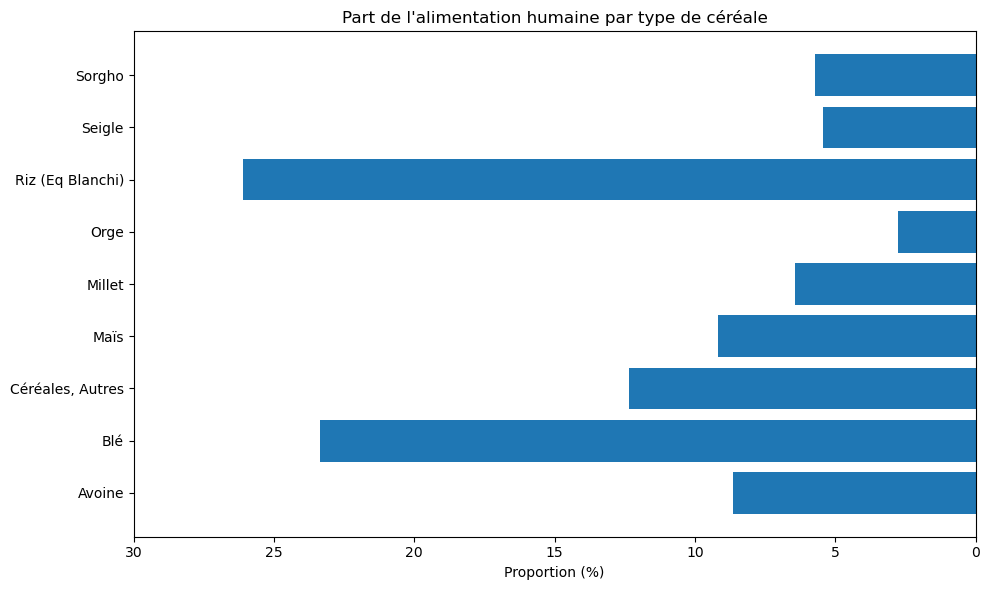

In [45]:
#Affichage de la proportion d'alimentation humaine
cereales['Proportion alimentation humaine'] = (cereales['Nourriture'] / cereales['Disponibilité intérieure']*100).round(2)
cereales['Proportion alimentation humaine'] = cereales['Proportion alimentation humaine'].fillna(0)
cereales['Proportion alimentation humaine'] = cereales['Proportion alimentation humaine'].replace([np.inf, -np.inf, np.nan], 0)

prop_cereales_humains = cereales[['Zone', 'Produit', 'Proportion alimentation humaine']]

cereales_pie_humains = prop_cereales_humains.groupby('Produit')['Proportion alimentation humaine'].sum()
cereales_pct_hum = (cereales_pie_humains / cereales_pie_humains.sum() * 100).round(2)

plt.figure(figsize=(10, 6))

plt.barh(
    cereales_pct_hum.index,
    cereales_pct_hum.values
)

plt.xlabel('Proportion (%)')
plt.title("Part de l'alimentation humaine par type de céréale")
plt.xlim(30, 0)

plt.tight_layout()
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.6 - Pays avec la proportion de personnes sous-alimentée la plus forte en 2017</h3>
</div>

In [46]:
#Création de la colonne proportion par pays

data_2017['Proportion'] = (data_2017['sous_nutrition'] / data_2017['Population']*100).round(2)

display(data_2017.head(10))

,Zone,Année,Population,sous_nutrition,Proportion
0,Afghanistan,2017,36296113,10500000.0,28.93
1,Afrique du Sud,2017,57009756,3100000.0,5.44
2,Albanie,2017,2884169,100000.0,3.47
3,Algérie,2017,41389189,1300000.0,3.14
4,Allemagne,2017,82658409,0.0,0.00
5,Andorre,2017,77001,0.0,0.00
6,Angola,2017,29816766,5800000.0,19.45
7,Antigua-et-Barbuda,2017,95426,0.0,0.00
8,Arabie saoudite,2017,33101178,1600000.0,4.83
9,Argentine,2017,43937140,1500000.0,3.41


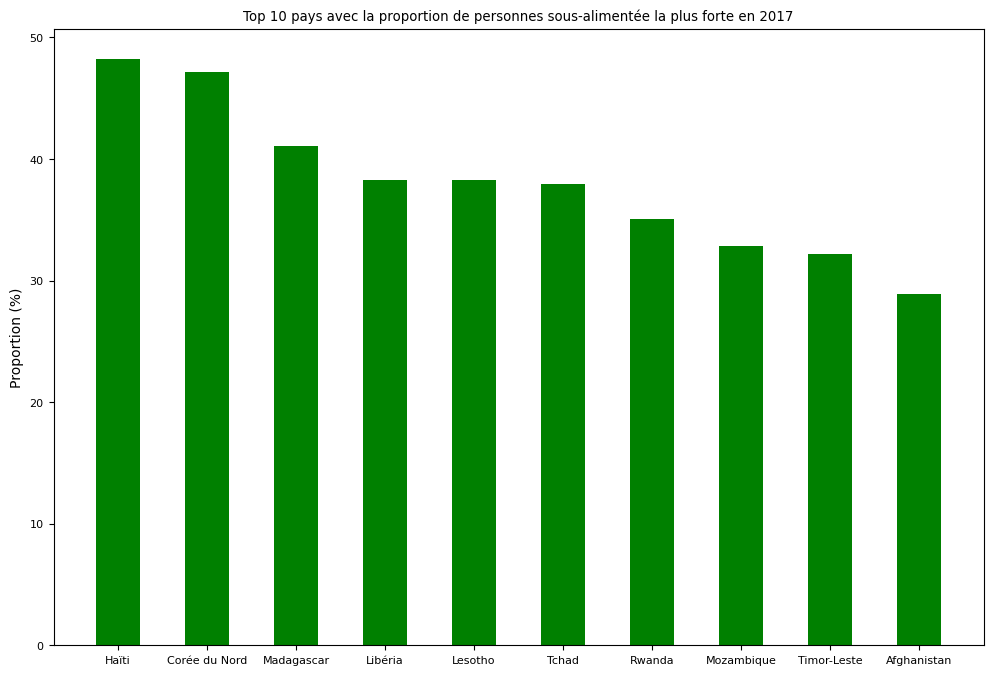

In [47]:
#affichage après trie des 10 pires pays
data_bar = data_2017.sort_values(by='Proportion', ascending=False).head(10)

data_bar = data_bar.replace({'République populaire démocratique de Corée': 'Corée du Nord'})
plt.figure(figsize=(12, 8))
plt.rcParams.update({'font.size': 8})
plt.ylabel('Proportion (%)', fontsize=10, rotation=90)  
plt.title('Top 10 pays avec la proportion de personnes sous-alimentée la plus forte en 2017')
plt.bar(height=data_bar['Proportion'], x=data_bar['Zone'], width=0.5, color='green', align='center');



<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.7 - Pays qui ont le plus bénéficié d'aide alimentaire depuis 2013</h3>
</div>

In [48]:
#calcul du total de l'aide alimentaire par pays
aide_alimentaire_all = aide_alimentaire.groupby('Zone').agg({
    'Produit': 'count',
    'Valeur': 'sum',
})

display(aide_alimentaire_all.head())

,Produit,Valeur
Zone,,
Afghanistan,16,185452000
Algérie,39,81114000
Angola,4,5014000
Bangladesh,25,348188000
Bhoutan,12,2666000


In [49]:
#affichage après trie des 10 pays qui ont bénéficié le plus de l'aide alimentaire
aide_alimentaire_all.sort_values(by='Valeur', ascending=False).head(10)

,Produit,Valeur
Zone,,
République arabe syrienne,38,1858943000
Éthiopie,33,1381294000
Yémen,38,1206484000
Soudan du Sud,22,695248000
Soudan,24,669784000
Kenya,27,552836000
Bangladesh,25,348188000
Somalie,27,292678000
République démocratique du Congo,25,288502000


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.8 - Evolution des 5 pays qui ont le plus bénéficiés de l'aide alimentaire entre 2013 et 2016</h3>
</div>

In [50]:
#Création d'un dataframe avec la zone, l'année et l'aide alimentaire puis groupby sur zone et année 
evolution = aide_alimentaire[['Zone', 'Année', 'Valeur']]

evolution = evolution.groupby(['Zone', 'Année']).agg({
    'Valeur': 'sum'
}).reset_index()

In [51]:
#Création d'une liste contenant les 5 pays qui ont le plus bénéficié de l'aide alimentaire
aide_liste = (
    evolution
    .groupby('Zone')['Valeur']
    .sum()
    .nlargest(5)
)

display(aide_liste.head())

Zone
République arabe syrienne    1858943000
Éthiopie                     1381294000
Yémen                        1206484000
Soudan du Sud                 695248000
Soudan                        669784000
Name: Valeur, dtype: int64

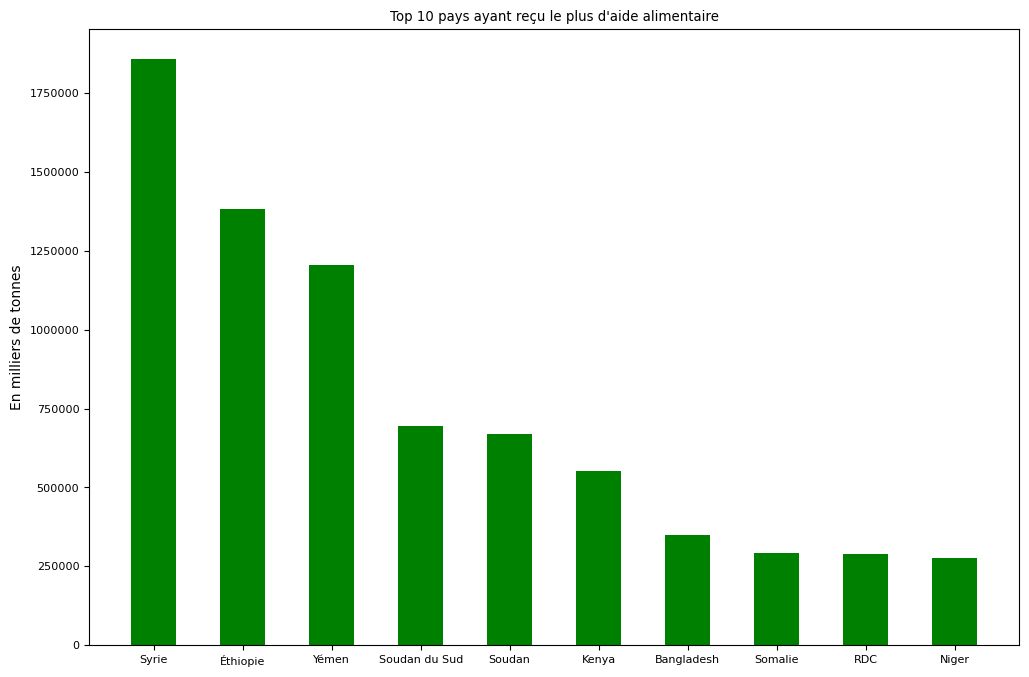

In [52]:
#Création d'un graphique présentant les 10 pays qui ont le plus bénéficié de l'aide alimentaire

aide_liste_bar = (
    evolution
    .groupby('Zone', as_index=False)['Valeur']
    .sum()
    .nlargest(10, 'Valeur')
)

aide_liste_bar['Valeur'] = aide_liste_bar['Valeur'] / 1000

aide_liste_bar = aide_liste_bar.replace({'République arabe syrienne': 'Syrie'})
aide_liste_bar = aide_liste_bar.replace({'République démocratique du Congo': 'RDC'})

plt.figure(figsize=(12, 8))
plt.rcParams.update({'font.size': 8})
plt.ylabel('En milliers de tonnes', fontsize=10, rotation=90)  
plt.title("Top 10 pays ayant reçu le plus d'aide alimentaire")
plt.ticklabel_format(style='plain', axis='y')
plt.bar(height=aide_liste_bar['Valeur'], x=aide_liste_bar['Zone'], width=0.5, color='green', align='center');

In [53]:
#On filtre sur le dataframe avec notre liste
top_pays = aide_liste.index.tolist()
aide_df = evolution[evolution['Zone'].isin(top_pays)]

In [54]:
# Affichage des pays avec l'aide alimentaire par année
display(aide_df.head(10))

,Zone,Année,Valeur
157,République arabe syrienne,2013,563566000
158,République arabe syrienne,2014,651870000
159,République arabe syrienne,2015,524949000
160,République arabe syrienne,2016,118558000
189,Soudan,2013,330230000
190,Soudan,2014,321904000
191,Soudan,2015,17650000
192,Soudan du Sud,2013,196330000
193,Soudan du Sud,2014,450610000
194,Soudan du Sud,2015,48308000


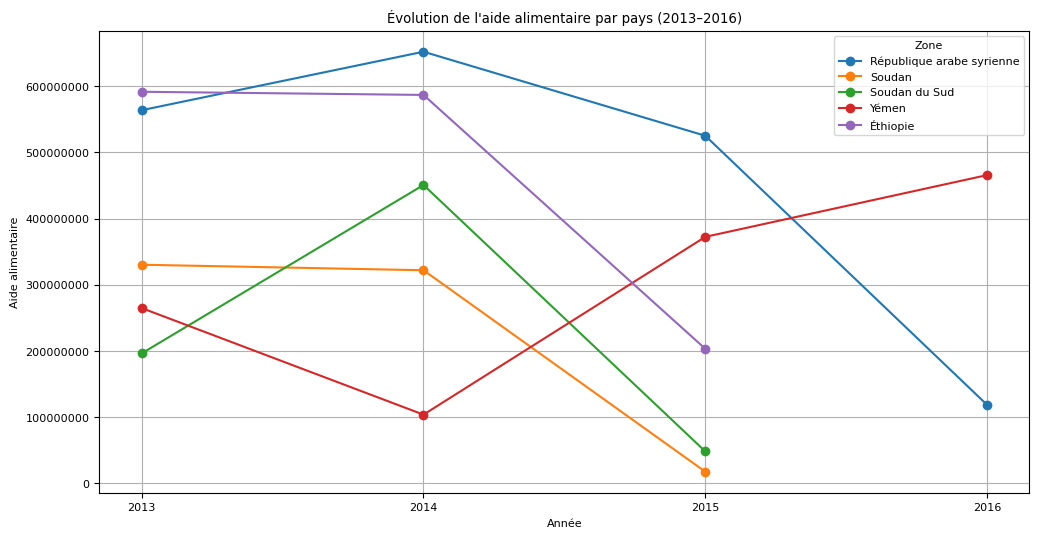

In [55]:
# Affichage de l'évolution de l'aide alimentaire pour le top 5

aide_df_pivot = aide_df.pivot(
    index="Année",
    columns="Zone",
    values="Valeur"
)
aide_df_pivot.plot(marker="o", figsize=(12, 6))
plt.title("Évolution de l'aide alimentaire par pays (2013–2016)")
plt.xlabel("Année")
plt.xticks([2013, 2014, 2015, 2016])
plt.ylabel("Aide alimentaire")
plt.ticklabel_format(style='plain', axis='y')
plt.grid(True)
plt.show()

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.9 - Pays avec le moins de disponibilité par habitant</h3>
</div>

In [56]:
# Calcul de la disponibilité en kcal par personne par jour par pays
down_dispo = dispo_alimentaire[['Zone', 'Disponibilité alimentaire (Kcal/personne/jour)']]

down_dispo = down_dispo.groupby('Zone').agg({
    'Disponibilité alimentaire (Kcal/personne/jour)': 'sum',
})


In [57]:
#Affichage des 10 pays qui ont le moins de dispo alimentaire par personne 
# Afficher le résultat
display(down_dispo.nsmallest(10, 'Disponibilité alimentaire (Kcal/personne/jour)'))

,Disponibilité alimentaire (Kcal/personne/jour)
Zone,
République centrafricaine,1879.0
Zambie,1924.0
Madagascar,2056.0
Afghanistan,2087.0
Haïti,2089.0
République populaire démocratique de Corée,2093.0
Tchad,2109.0
Zimbabwe,2113.0
Ouganda,2126.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.10 - Pays avec le plus de disponibilité par habitant</h3>
</div>

In [58]:
#Affichage des 10 pays qui ont le plus de dispo alimentaire par personne 

display(down_dispo.nlargest(10, 'Disponibilité alimentaire (Kcal/personne/jour)'))

,Disponibilité alimentaire (Kcal/personne/jour)
Zone,
Autriche,3770.0
Belgique,3737.0
Turquie,3708.0
États-Unis d'Amérique,3682.0
Israël,3610.0
Irlande,3602.0
Italie,3578.0
Luxembourg,3540.0
Égypte,3518.0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">3.11 - Exemple de la Thaïlande pour le Manioc</h3>
</div>

In [59]:
#Création d'un dataframe avec uniquement la Thaïlande 

thailande_sn = sous_nutrition_valeur.copy()
pop_thailande = population[population['Année'] == 2017]
pop_thailande = pop_thailande[pop_thailande['Zone'] == 'Thaïlande']

thailande_sn = thailande_sn.replace('2016-2018', '2017')
thailande_sn = thailande_sn[thailande_sn['Année'] == '2017']
thailande_sn = thailande_sn[thailande_sn['Zone'] == 'Thaïlande']
thailande_sn['Année'] = thailande_sn['Année'].astype('Int64')

thailande_nut = pd.merge(pop_thailande, thailande_sn, on=['Zone', 'Année'])

thai_dispo = dispo_alimentaire.copy()
thailande_nut = pd.merge(thailande_nut, thai_dispo, on=['Zone'])

In [60]:
#Calcul de la sous nutrition en Thaïlande

thai_2017 = thailande_nut.copy()
thai_2017 = thai_2017.groupby('Zone').agg({
    'Zone': 'first',
    'Année': 'first',
    'Population': 'first',
    'sous_nutrition': 'first'
})

thai_2017 = thai_2017[thai_2017['Zone'] == 'Thaïlande']

thai_sousnutrition = ((thai_2017['sous_nutrition']) / (thai_2017['Population'])*100).round(2).iloc[0]

display(thai_2017)
print(f"Le taux de sous-nutrition en Thaïlande est de {thai_sousnutrition} %")

,Zone,Année,Population,sous_nutrition
Zone,,,,
Thaïlande,Thaïlande,2017,69209810,6200000.0


Le taux de sous-nutrition en Thaïlande est de 8.96 %


In [61]:
#On calcule la proportion exportée de manioc en fonction de la production 

thailande_manioc = dispo_alimentaire[dispo_alimentaire['Zone'] == 'Thaïlande']
thailande_manioc = thailande_manioc[thailande_manioc['Produit'] == 'Manioc']

manioc_export = ((thailande_manioc['Exportations - Quantité'] / thailande_manioc['Production']) * 100).round(2)

display(thailande_manioc[['Zone', 'Produit', 'Exportations - Quantité', 'Production']])
print(f"La proportion de manioc exportée par la Thaïlande est de {manioc_export.iloc[0]} %")

dispo_thai = dispo_alimentaire[dispo_alimentaire['Zone'] == 'Thaïlande']
dispo_thai = pd.merge(dispo_thai, pop_thailande, on=['Zone'])

dispo = (dispo_thai['Disponibilité alimentaire en quantité (kg/personne/an)'].sum() / 365 * 1000).round(2)

print(f"La disponibilité par habitant est de {dispo} g / jour")

,Zone,Produit,Exportations - Quantité,Production
13809,Thaïlande,Manioc,25214000.0,30228000.0


La proportion de manioc exportée par la Thaïlande est de 83.41 %
La disponibilité par habitant est de 1606.11 g / jour


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 6 - Analyse complémentaires</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">Création d'une carte affichant le taux de sous-nutrition par pays en 2017</h3>
</div>

In [62]:
#On crée un nouveau dataframe pour afficher une carte de la proportion de la sous-nutrition par pays en 2017
data_map = sous_nutrition.copy()

data_map = data_map.replace('2016-2018', '2017')
data_map = data_map[data_map['Année'] == '2017']

data_map['Année'] = data_map['Année'].astype(int)

data_world = pd.merge(population_2017, data_map, on=['Zone', 'Année'])

mask_inf = data_world['Valeur'] == '<0.1'

data_world.loc[~mask_inf, 'Valeur'] = pd.to_numeric(
    data_world.loc[~mask_inf, 'Valeur'],
    errors='coerce'
)
data_world.loc[~mask_inf, 'Valeur'] = data_world.loc[~mask_inf, 'Valeur'] * 1000000

valeur_num = pd.to_numeric(
    data_world.loc[~mask_inf, 'Valeur'],
    errors='coerce'
)

data_world.loc[~mask_inf, 'Proportion'] = (valeur_num / data_world.loc[~mask_inf, 'Population'] * 100).round(2)

data_world.loc[mask_inf, 'Proportion'] = '<0.1'

world_sous_nutrition = pd.merge(population_2017, data_world, on=['Zone', 'Année', 'Population'])

countries_iso = world_sous_nutrition[['Zone', 'Proportion']]

countries = pd.read_csv('C:/Users/capel/Downloads/Projet 4/DAN-P4-FAO/country-codes.csv')

countries_iso = countries_iso.merge(
    countries[['official_name_fr','ISO3166-1-Alpha-3']], 
    left_on='Zone', right_on='official_name_fr', how='left'
)

countries_iso = countries_iso.rename(columns={'ISO3166-1-Alpha-3': 'ISO'})

C:\Users\capel\AppData\Local\Temp\ipykernel_24112\3625084644.py:26: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '<0.1' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  data_world.loc[mask_inf, 'Proportion'] = '<0.1'


C:\Users\capel\AppData\Local\Temp\ipykernel_24112\4118934491.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  countries_iso['Proportion Numérique'] = pd.to_numeric(countries_iso['Proportion'].replace('<0.1', 0.05), errors='coerce')


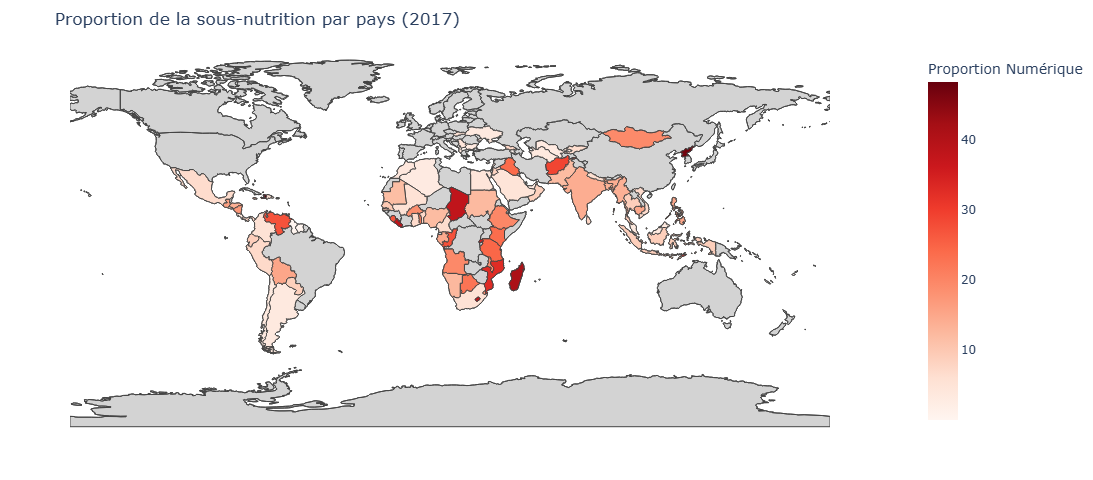

In [63]:
#Maintenant que l'on a les ISO, on peut utiliser Plotly
#On affiche les pays ayant une sous-nutrition de <0.1 afin de les différencier des pays ayant NaN. Les pays gris sur la carte sont les pays ayant NaN.

import plotly.express as px

countries_iso['Proportion Numérique'] = pd.to_numeric(countries_iso['Proportion'].replace('<0.1', 0.05), errors='coerce')

fig = px.choropleth(
    countries_iso,
    locations="ISO",
    color="Proportion Numérique",
    hover_name="Zone",
    color_continuous_scale="Reds",
    title="Proportion de la sous-nutrition par pays (2017)",
    width=960,
    height=480
)

fig.update_traces(
    hovertemplate="<b>%{hovertext}</b><br>Sous-nutrition: %{customdata}<extra></extra>",
    customdata=countries_iso['Proportion'] 
)

fig.update_layout(
    autosize=True,
    margin={"r":0,"t":50,"l":0,"b":50}, 
)

fig.update_geos(
    showcountries=True,
    showcoastlines=True,
    landcolor="lightgrey",
    showland=True,
    fitbounds="locations",
    visible=False,
)

fig.show()